## Settings

In [1]:
## auto reload modules
%reload_ext autoreload
%autoreload 2

## Dependencies

In [ ]:
## libraries
import sys
import pickle
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

## path
root = Path.cwd().resolve().parent
sys.path.insert(0, str(root))

## modules
from src.evaluators.caching import load_notebook_cache
from src.evaluators.utilizing import (
    load_utilization_data,
    compile_corpus_table,
    precompute_native_sct_regime,
    run_9_config_benchmark,
    compile_cross_regime_table,
    compile_system_predictions_table,
    plot_utilization_triad,
)

## constants
from src.estimators.config import (
    ASYMMETRY_C,
    ASYMMETRY_R,
    ALPHA,
)
from src.evaluators.config import (
    FEAT_X,
    FEAT_Z,
    TARGET,
)
from src.evaluators.utilizing import (
    REDUCED_6_DESC,
    GLM_FAMILIES,
    SCT_MODES
)

## Initialization

In [3]:
## reproducibility
N_DECIMALS = 2
RANDOM_STATE = 42
FORCE_RECOMPUTE = False
np.random.seed(RANDOM_STATE)

## load data
data = load_utilization_data()
df_t1 = compile_corpus_table(df_data = data)

## view data and feature surface
print(f"Original Data: {len(FEAT_X) + len(FEAT_Z)} native features, {len(data)} observations")
print(f"Native SCT Frontier Inputs:   21 FEAT_X + 7 FEAT_Z = {len(FEAT_X) + len(FEAT_Z)} features (LinearQuantile: tau_C={ASYMMETRY_C}, tau_R={ASYMMETRY_R}, alpha={ALPHA})")
print(f"Downstream Typical-Rate Set:  3 REDUCED_3_X + 3 REDUCED_3_Z (fano_factor omitted) = {len(REDUCED_6_DESC)} features: {REDUCED_6_DESC}")

## cache setup
cache_path = root / "notebooks" / "cache" / "utilize_results.pkl"
cache_metadata = {
    "n_obs": len(data),
    "random_state": RANDOM_STATE,
    "target": TARGET,
    "feat_x": list(FEAT_X),
    "feat_z": list(FEAT_Z),
    "reduced_6_desc": list(REDUCED_6_DESC),
    "glm_families": list(GLM_FAMILIES),
    "sct_modes": list(SCT_MODES),
    "rho_rescaled": True,
}
cache_keys = (
    "sct_native_oof",
    "df_9_disc",
    "preds_9_disc",
    "regime_dfs",
    "df_cross",
    "df_sys",
)
cache_payload = load_notebook_cache(
    cache_path = cache_path,
    metadata = cache_metadata,
    required_keys = cache_keys,
    force_recompute = FORCE_RECOMPUTE,
)
if cache_payload is not None:
    globals().update({key: cache_payload[key] for key in cache_keys})

Original Data: 28 native features, 25 observations
Native SCT Frontier Inputs:   21 FEAT_X + 7 FEAT_Z = 28 features (LinearQuantile: tau_C=0.99, tau_R=0.5, alpha=0.1)
Downstream Typical-Rate Set:  3 REDUCED_3_X + 3 REDUCED_3_Z (fano_factor omitted) = 6 features: ['n_edges', 'degree_entropy', 'random_walk_triangle_weight', 'norm_succ_diff', 'coef_variation', 'trend_coeff']
Loaded results from /Users/nickkunz/Documents/Nick’s MacBook Pro/Python/network-capacity/notebooks/cache/utilize_results.pkl


## Training

In [4]:
## leave-one-group-out cross validation (discipline)
if cache_payload is None:
    native_folds_disc = precompute_native_sct_regime(
        df_data = data,
        regime_name = "Discipline LOGO-CV",
        random_state = RANDOM_STATE,
    )
    sct_native_oof = np.zeros(len(data), dtype = float)
    for _, te_i, _, s_te, _ in native_folds_disc:
        sct_native_oof[te_i] = s_te

    df_9_disc, preds_9_disc = run_9_config_benchmark(
        df_data = data,
        folds = native_folds_disc,
        reduced_cols = REDUCED_6_DESC,
    )

In [5]:
## cross-regime resampling evaluation (domain logo, 5-fold, 10-fold)
if cache_payload is None:
    regime_dfs = {"Discipline LOGO-CV": df_9_disc}
    for reg_name in ("Domain LOGO-CV", "5-Fold-CV", "10-Fold-CV"):
        nf_r = precompute_native_sct_regime(
            df_data = data,
            regime_name = reg_name,
            random_state = RANDOM_STATE,
        )
        df_r, _ = run_9_config_benchmark(
            df_data = data,
            folds = nf_r,
            reduced_cols = REDUCED_6_DESC,
        )
        regime_dfs[reg_name] = df_r

## Post-Processing

In [6]:
## compile tables and persist cache
if cache_payload is None:
    df_cross = compile_cross_regime_table(regime_dfs = regime_dfs)
    df_sys = compile_system_predictions_table(
        df_data = data,
        sct_native_oof = sct_native_oof,
        preds_disc = preds_9_disc,
        family = "Negative Binomial",
    )

    cache_path.parent.mkdir(parents = True, exist_ok = True)
    cache_payload = {
        "metadata": cache_metadata,
        "sct_native_oof": sct_native_oof,
        "df_9_disc": df_9_disc,
        "preds_9_disc": preds_9_disc,
        "regime_dfs": regime_dfs,
        "df_cross": df_cross,
        "df_sys": df_sys,
    }
    cache_path.write_bytes(pickle.dumps(cache_payload))
    print(f"Cached utilization results -> {cache_path}")

## Table 1: Typical Rate vs. Empirical Maximum Across All 25 N3S Systems
Both the empirical maximum capacity $r_{\max, i} = \max_{1 \le t \le L_i} r_{i, t}$ and the typical activity rate $\bar{r}_{\mathrm{typ}, i} = M_i / L_i$ are evaluated over the $L_i$ observed intervals for each system.

In [7]:
## display corpus typical-rate vs. empirical-maximum summary
display(df_t1)

,name,domain,L,M,r_typ,r_max,Util_%,y_typ,y_max
0,amazon,Trade & Institutions,6296,22507155,3574.83,37293.0,9.59,8.18,10.53
1,auger,Earth & Physical Sciences,4871,81155,16.66,66.0,25.24,2.87,4.20
2,bitcoin,Trade & Institutions,1769,35592,20.12,319.0,6.31,3.05,5.77
3,celegans,Life Sciences & Medicine,18,39,2.17,8.0,27.08,1.15,2.20
4,chickenpox,Life Sciences & Medicine,522,57931,110.98,378.0,29.36,4.72,5.94
5,college,Technology & Information,193,59835,310.03,2678.0,11.58,5.74,7.89
6,crop,Life Sciences & Medicine,129,20529,159.14,1266.0,12.57,5.08,7.14
7,email,Technology & Information,526,332334,631.81,2270.0,27.83,6.45,7.73
8,epilepsy,Life Sciences & Medicine,50,198,3.96,27.0,14.67,1.60,3.33
9,faers,Life Sciences & Medicine,2616,9344,3.57,45.0,7.94,1.52,3.83


## Table 2: 9-Configuration Discrete Count GLM Triad Benchmark
Evaluates the three discrete count GLM families ordered by variance power $p \in \{1,\, 1.75,\, 2\}$ (`Poisson`, `Poisson-Tweedie`, `Negative Binomial`) across the three SCT regimes (`Without SCT`, `SCT as a Feature`, `SCT plus Correction`) under the canonical decomposition:
$$\text{SCT Frontier} - \bigl(\text{EVT Statistic} + \text{Log-Rate Utilization}\bigr) = \text{Log-Rate Estimation}$$

In [8]:
## display 9-configuration triad benchmark (discipline logo-cv)
display(df_9_disc)

,Model_Family,SCT_Integration,SCT_Slope_Wt,Typ_Log_MAE,GMean_Mult_x,Med_Mult_x,Within_2x_%,Within_3x_%,rho,RBO,dCor,CI,Mean_LogLik,Cov_90_%
0,Poisson,Without SCT,0.000,3.022,23.36,17.30,8.0,20.0,0.825,0.556,0.634,0.662,-1.241553e+08,0.0
1,Poisson,SCT as a Feature,0.402,2.655,16.34,14.50,8.0,16.0,0.947,0.658,0.886,0.821,-7.888911e+07,0.0
2,Poisson,SCT plus Correction,1.000,0.698,2.18,1.85,60.0,76.0,0.976,0.951,0.989,0.972,-9.258342e+06,0.0
3,Poisson-Tweedie,Without SCT,0.000,1.660,5.84,4.45,32.0,40.0,0.909,0.680,0.789,0.787,-3.270000e+01,88.0
4,Poisson-Tweedie,SCT as a Feature,0.844,0.426,1.66,1.53,68.0,92.0,0.983,0.982,0.987,0.984,-1.183000e+01,88.0
5,Poisson-Tweedie,SCT plus Correction,1.000,0.273,1.41,1.27,84.0,100.0,0.985,0.976,0.995,0.985,-1.068000e+01,84.0
6,Negative Binomial,Without SCT,0.000,1.546,5.18,2.99,40.0,52.0,0.914,0.714,0.805,0.807,-1.362000e+01,80.0
7,Negative Binomial,SCT as a Feature,0.833,0.411,1.64,1.30,68.0,92.0,0.980,0.985,0.986,0.984,-1.123000e+01,68.0
8,Negative Binomial,SCT plus Correction,1.000,0.263,1.39,1.26,84.0,100.0,0.989,0.963,0.996,0.982,-1.074000e+01,80.0


## Table 3: Cross-Regime Typical-Rate Consistency
Out-of-sample Typical-Rate Log MAE and Consensus Index (`CI`) across all four N3S resampling regimes (`Discipline LOGO-CV`, `Domain LOGO-CV`, `5-Fold-CV`, `10-Fold-CV`).

In [9]:
## display cross-regime consistency table
display(df_cross)

,Model_Family,SCT_Integration,Disc_LOGO_MAE,Domain_LOGO_MAE,5Fold_CV_MAE,10Fold_CV_MAE,Disc_LOGO_CI,Domain_LOGO_CI,5Fold_CV_CI,10Fold_CV_CI
0,Poisson,Without SCT,3.022,3.255,2.899,3.000,0.662,0.602,0.667,0.622
1,Poisson,SCT as a Feature,2.655,2.821,2.774,2.739,0.821,0.818,0.776,0.779
2,Poisson,SCT plus Correction,0.698,0.804,0.696,0.784,0.972,0.974,0.970,0.973
3,Poisson-Tweedie,Without SCT,1.660,1.461,1.488,1.742,0.787,0.823,0.866,0.755
4,Poisson-Tweedie,SCT as a Feature,0.426,0.495,0.457,0.446,0.984,0.980,0.976,0.976
5,Poisson-Tweedie,SCT plus Correction,0.273,0.316,0.330,0.338,0.985,0.984,0.985,0.985
6,Negative Binomial,Without SCT,1.546,1.450,1.444,1.558,0.807,0.847,0.872,0.803
7,Negative Binomial,SCT as a Feature,0.411,0.488,0.449,0.439,0.984,0.975,0.978,0.978
8,Negative Binomial,SCT plus Correction,0.263,0.316,0.347,0.337,0.982,0.983,0.980,0.982


## Table 4: System-by-System Typical-Rate Predictions
Out-of-sample typical-rate point predictions and 90% prediction intervals across all 25 N3S systems (`Negative Binomial`, `Discipline LOGO-CV`).

In [10]:
## display system-by-system typical-rate predictions
display(df_sys)

,System,Domain,Intervals_L,Obs_r_typ,Obs_y_typ,Native_SCT_y*,NoSCT_y_typ,SCT_Feat_y_typ,SCT_Corr_y_typ,SCT_Corr_r_typ,NB_90%_TypRate_CI
0,amazon,Trade & Institutions,6296,3574.83,8.18,18.96,8.99,8.23,8.16,3505.61,"[1698.80, 5838.51]"
1,auger,Earth & Physical Sciences,4871,16.66,2.87,13.23,4.42,3.07,2.95,18.13,"[7.73, 32.06]"
2,bitcoin,Trade & Institutions,1769,20.12,3.05,13.06,6.52,3.78,3.10,21.13,"[10.26, 35.15]"
3,celegans,Life Sciences & Medicine,18,2.17,1.15,10.98,3.45,1.99,1.86,5.45,"[2.44, 9.39]"
4,chickenpox,Life Sciences & Medicine,522,110.98,4.72,14.45,5.23,4.90,5.02,149.72,"[62.97, 266.47]"
5,college,Technology & Information,193,310.03,5.74,16.30,5.20,5.53,5.72,304.22,"[140.37, 518.89]"
6,crop,Life Sciences & Medicine,129,159.14,5.08,14.92,2.59,4.14,4.66,104.93,"[45.37, 184.45]"
7,email,Technology & Information,526,631.81,6.45,15.83,6.86,6.43,6.42,614.15,"[266.01, 1078.77]"
8,epilepsy,Life Sciences & Medicine,50,3.96,1.60,11.42,1.66,1.40,1.47,3.34,"[1.50, 5.74]"
9,faers,Life Sciences & Medicine,2616,3.57,1.52,11.17,7.87,2.87,1.48,3.39,"[1.63, 5.68]"


## Visualization: 9-Configuration Discrete Count Triad & Native SCT Capacity Backstop

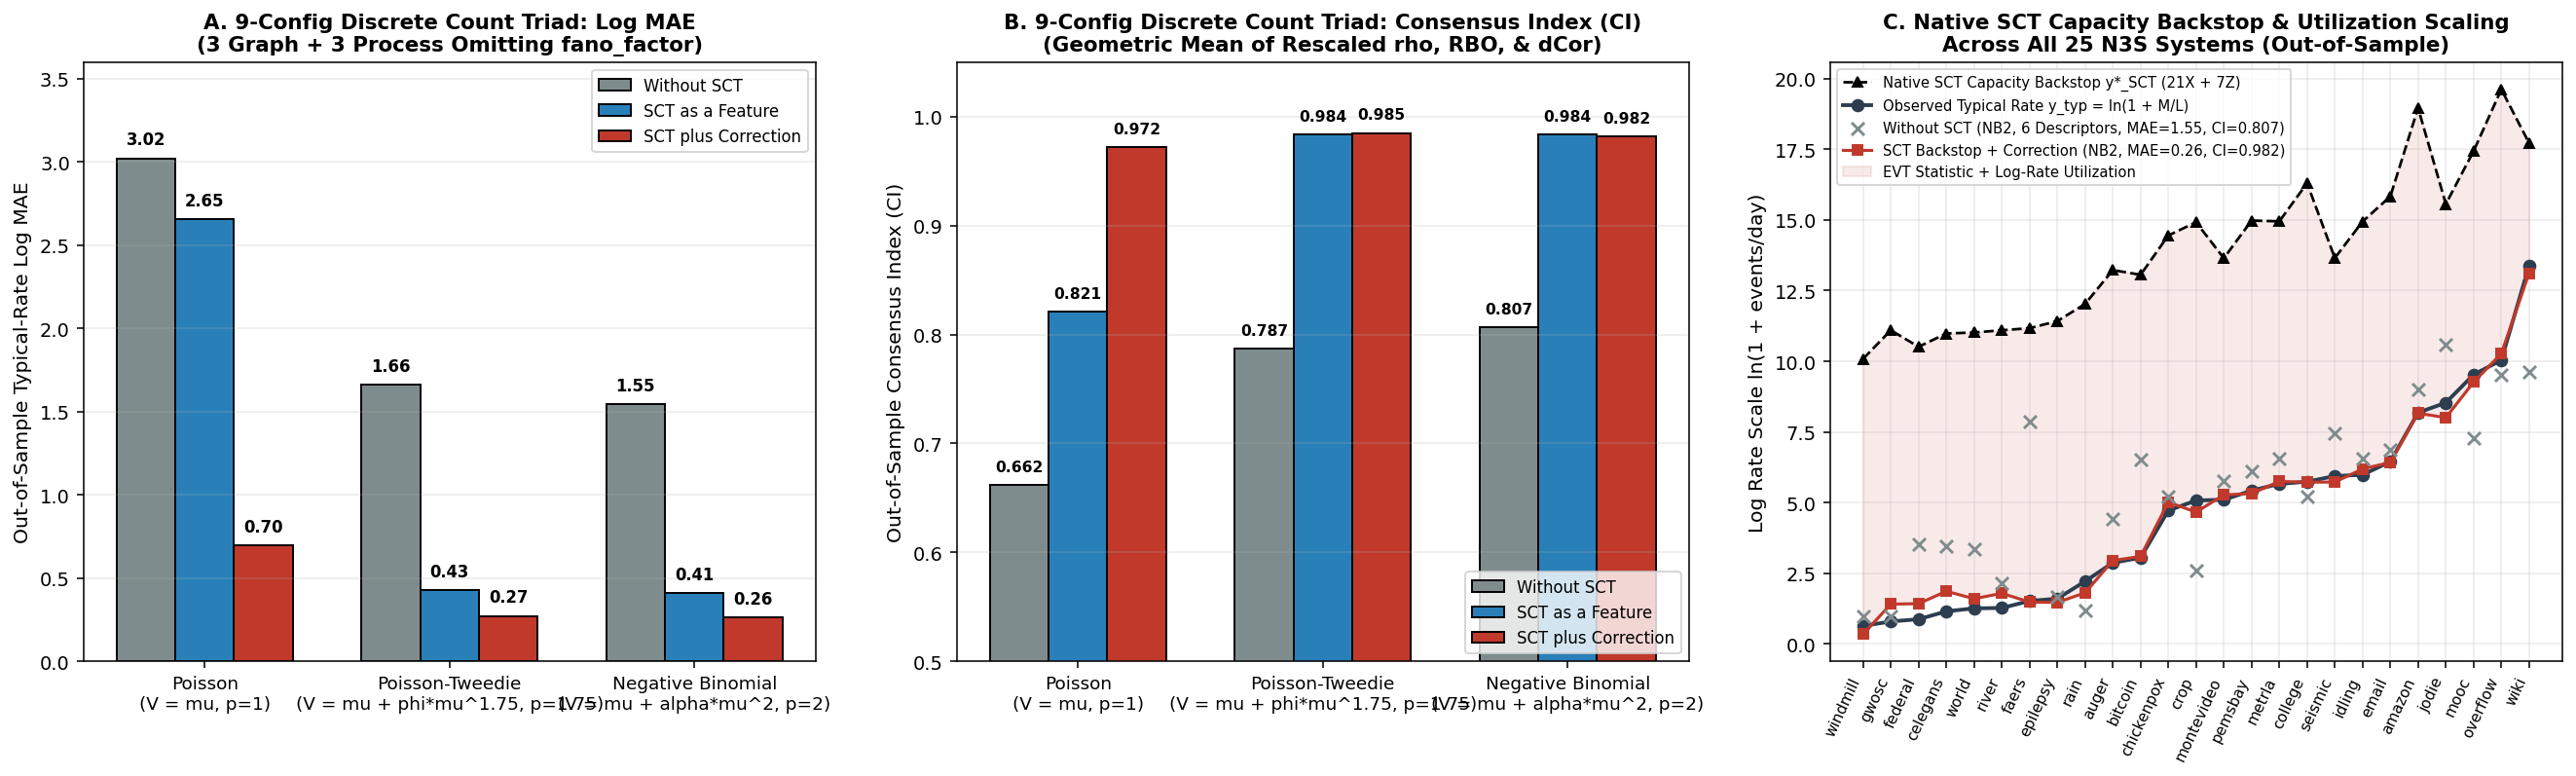

In [11]:
## plot 3-panel 9-configuration discrete count triad figure
fig = plot_utilization_triad(
    df_data = data,
    df_9_disc = df_9_disc,
    preds_9_disc = preds_9_disc,
    sct_native_oof = sct_native_oof,
)
plt.show()